# Equations différentielles ordinaires

---

*Commencez par créer un dossier `TP05_edo` destiné à accueillir tous les scripts de ce TP. Pensez à tester tous vos programmes un par un.*

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
mpl.rcParams['savefig.dpi'] = 80

#### Exercice 1

> Créez un module (fichier `python`) intitulé `mes_fonctions.py` et y coder la fonction `idt(t, x)` qui correspond à la fonction mathématique $(t, x)\mapsto t$, où $t$ et $x$ sont des réels

Par la suite, nous importerons ce module sous l'alias `f` (`import mes_fonctions as f`).

*Indication* : le fichier `mes_fonctions.py` pourrait contenir les lignes suivantes

```python
"""
module mes_fonctions
contenant les fonctions nécessaires au TP05
sur les EDO

@Benjamin Graille
"""


def idt(t, x):
    """
    fonction (t, x) -> t

    t, x: double
    
    return t
    """
    return
```

In [2]:
%%writefile TP05_EDO/test.py

import numpy as np

Writing TP05_EDO/test.py


## 1. Mon premier schéma : la méthode d'Euler explicite

Pour $f : (t, x) \in \mathbb{R^{2}} \rightarrow \mathbb{R}$ de classe $C^{1}$, on considère le problème de Cauchy suivant
$$
 \left\lbrace
    \begin{aligned}
        &y^{\prime}(t)=f(t,y), && t\geq t_0,  \\
        &y(t_{0})=y_{0}.
    \end{aligned}
\right.
\qquad\qquad\qquad (1)
$$

On admet que le cadre mathématique est « bon » : en particulier, la solution existe et elle est unique ; cela est vrai pour tout couple $(t_{0}, y_{0})$. 

On notera $y : t \rightarrow y(t)$ cette solution.

Nous cherchons à approcher la solution à l’aide de l’ordinateur sur un intervalle de temps $[0 ,T]$. **On parle de résolution numérique.**

Au lieu de calculer cette solution en tout temps, nous allons chercher une approximation de cette solution à des temps particuliers qui découpent $[0,T]$ en petits intervalles où la solution varie peu. Cela s’appelle la discrétisation. La façon la plus simple de procéder est de choisir $N$ grand puis d’approcher la solution aux instants $t_{n} = t_{0} + nh$ où $h = \frac{T}{N}$ et $n = 1, \ldots, N$. Les mathématiques appliquées fournissent alors des relations de récurrence, appelées schémas, permettant de calculer $u_{n+1}$ à partir de $u_{n}$. Comme on part de $u_{0} = y_{0}$, il reste à calculer ces termes un par un jusqu’à $n = N$.

Le schéma d’Euler explicite est le schéma le plus simple pour discrétiser une **EDO**. 

Nous admettrons qu’il « approche » bien la solution exacte. Il est définit par:
$$
 \left\{
    \begin{aligned}
        &x_{0}=y_{0},  \\
        &x_{n+1}=x_{n}+h f(t_{n},x_{n}), &&n\geq 0.
    \end{aligned}
\right.
\qquad\qquad\qquad (2)
$$

#### Exercice 2

Commençons par tester ce schéma pour $f:(t, x)\mapsto t$ (la fonction `idt` du script `mes_fonctions.py`). Créez un module `python` intitulé `solve_edo.py` : mettez un commentaire pour le module, ajoutez les `import` nécessaires.

> * Rappelez la solution analytique de l'équation pour $(t_0, y_0) = (0, y_0)$.
> * Dans le fichier `solve_edo.py`, créez une fonction `step_euler` qui prend en argument trois réels `t`, `x` et `h` et une fonction `f` à deux variables réelles et qui renvoie l'approximation de la solution à l'aide du schéma à l'instant `t+h`.
> * Dans le même fichier, proposez une fonction `my_euler` qui prend en argument trois réels `t0`, `x0`, `T`, un entier `N` et une fonction `f` à deux variables réeles et qui
>    - calcule `h=T/N` ;
>    - crée deux tableaux `t` et `x` de taille `N+1` (de dimension 1) ;
>    - calcule chacun des instants `tn` et des approximations de la solution `xn` à l'aide du schéma d'Euler explicite et les stocke dans les vecteurs `t` et `x` ;
>    - renvoie les deux vecteurs `t` et `x`.
> * Afin de tester notre algorithme, tracez dans une fenêtre graphique la solution approchée ainsi que la solution exacte pour $(t_0, x_0)=(0, 0)$, $T=10$ et $N=50$.

*Essayez d'obtenir une figure comme celle-ci :*

![exo2](TP05_edo/exo2_1.png)

In [2]:
import TP05_edo.mes_fonctions as f
import TP05_edo.solve_edo as sedo

In [3]:
t0, x0 = 0., 0.
T = 10
N = 50

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(1, 1, 1)

t, x = sedo.my_euler(t0, x0, T, N, f.idt)
ax.scatter(
    t, x,
    s=25, color='orange', alpha=.5,
    label=f'EE $N={N}$'
)

tt = np.linspace(t0, T, 1025)
ax.plot(
    tt, x0 + .5*(tt-t0)**2,
    color='navy', lw=2,
    label='exact'
)
ax.legend()
ax.set_xlabel('$t$')
ax.set_ylabel('$x$')
ax.set_title("Solution de l'EDO")
plt.savefig("TP05_edo/exo2_1.png")

NameError: name 'plt' is not defined

> * Sur une nouvelle figure découpée en deux axes,
>   - sur l'axe de gauche, tracez la solution exacte ainsi que la solution approchée pour différentes valeurs de $N$ (par exemple $N\in\lbrace 5, 10, 50, 100, 200\rbrace$).
>   - sur l'axe de droite, tracez l'écart entre la solution approchée et la solution exacte pour les différentes valeurs de $N$. 

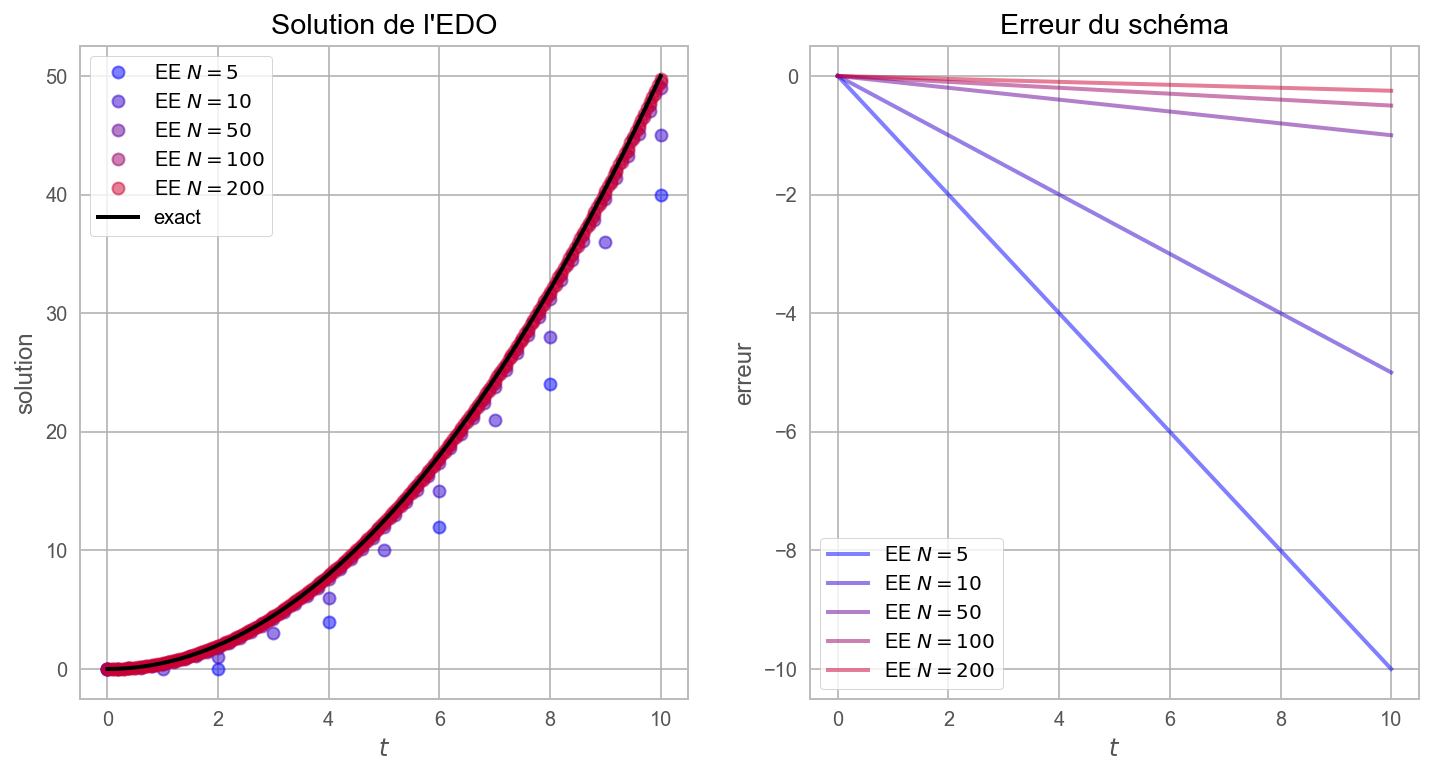

In [4]:
t0, x0 = 0., 0.
T = 10

fig = plt.figure(figsize=(12, 6))
axf = fig.add_subplot(1, 2, 1)
axe = fig.add_subplot(1, 2, 2)

liste_N = [5, 10, 50, 100, 200]
for k, N in enumerate(liste_N):
    c = (k/len(liste_N), 0, 1-k/len(liste_N))
    t, x = sedo.my_euler(t0, x0, T, N, f.idt)
    axf.plot(
        t, x,
        lw=2, color=c, alpha=.5,
        marker='o', linestyle='None',
        label=f'EE $N={N}$'
    )
    axe.plot(
        t, x - (x0 + .5*(t-t0)**2),
        lw=2, color=c, alpha=.5,
        label=f'EE $N={N}$'
    )

tt = np.linspace(t0, T, 1025)
axf.plot(
    tt, x0 + .5*(tt-t0)**2,
    color='black', lw=2,
    label='exact'
)
axf.legend()
axf.set_xlabel('$t$')
axf.set_ylabel('solution')
axf.set_title("Solution de l'EDO")
axe.legend()
axe.set_xlabel('$t$')
axe.set_ylabel('erreur')
axe.set_title("Erreur du schéma")

plt.savefig("TP05_edo/exo2_2.png")

## D'autres fonctions plus difficiles

#### Exercice 3

> Les fonctions suivantes sont à ajouter au fichier `mes_fonctions.py` :
> * la fonction $(t, x)\mapsto x$ nommée `idx`;
> * la fonction $(t, x)\mapsto x+\cos(t)$ nommée `my_f`;
> * la fonction $t\mapsto e^t$ nommée `my_exp`;

#### Exercice 4

On considère l'équation différentielle $x'(t)=x(t)$ avec la condition $x_0=1$.

> * En utilisant la fonction `my_euler` et en s'inspirant du script précédent, proposez un script `python` qui calcule une approximation de $e=x(1)$ en intégrant cette équation avec la méthode d'Euler explicite.
> * Testez pour différentes valeurs de $N$ et tracez l'erreur en fonction de $h=1/N$.

*Indication : vous pourrez utiliser les commandes `ax.set_xscale('log')` et `ax.set_yscale('log')` pour visualiser l'erreur en échelle logarithmique.*

In [5]:
t0, x0 = 0, 1
T = 1

vN = 2**np.arange(1, 12)
vh = 1/vN
ve = np.empty(vh.shape)
for k, h in enumerate(vh):
    ve[k] = sedo.my_euler(t0, x0, T, vN[k], f.idx)[1][-1]
    print(f"h={h:10.3e} => e ~ {ve[k]:10.7f}")
print(f"                e = {np.exp(1):10.7f}")

h= 5.000e-01 => e ~  2.2500000
h= 2.500e-01 => e ~  2.4414062
h= 1.250e-01 => e ~  2.5657845
h= 6.250e-02 => e ~  2.6379285
h= 3.125e-02 => e ~  2.6769901
h= 1.562e-02 => e ~  2.6973450
h= 7.812e-03 => e ~  2.7077390
h= 3.906e-03 => e ~  2.7129916
h= 1.953e-03 => e ~  2.7156320
h= 9.766e-04 => e ~  2.7169557
h= 4.883e-04 => e ~  2.7176185
                e =  2.7182818


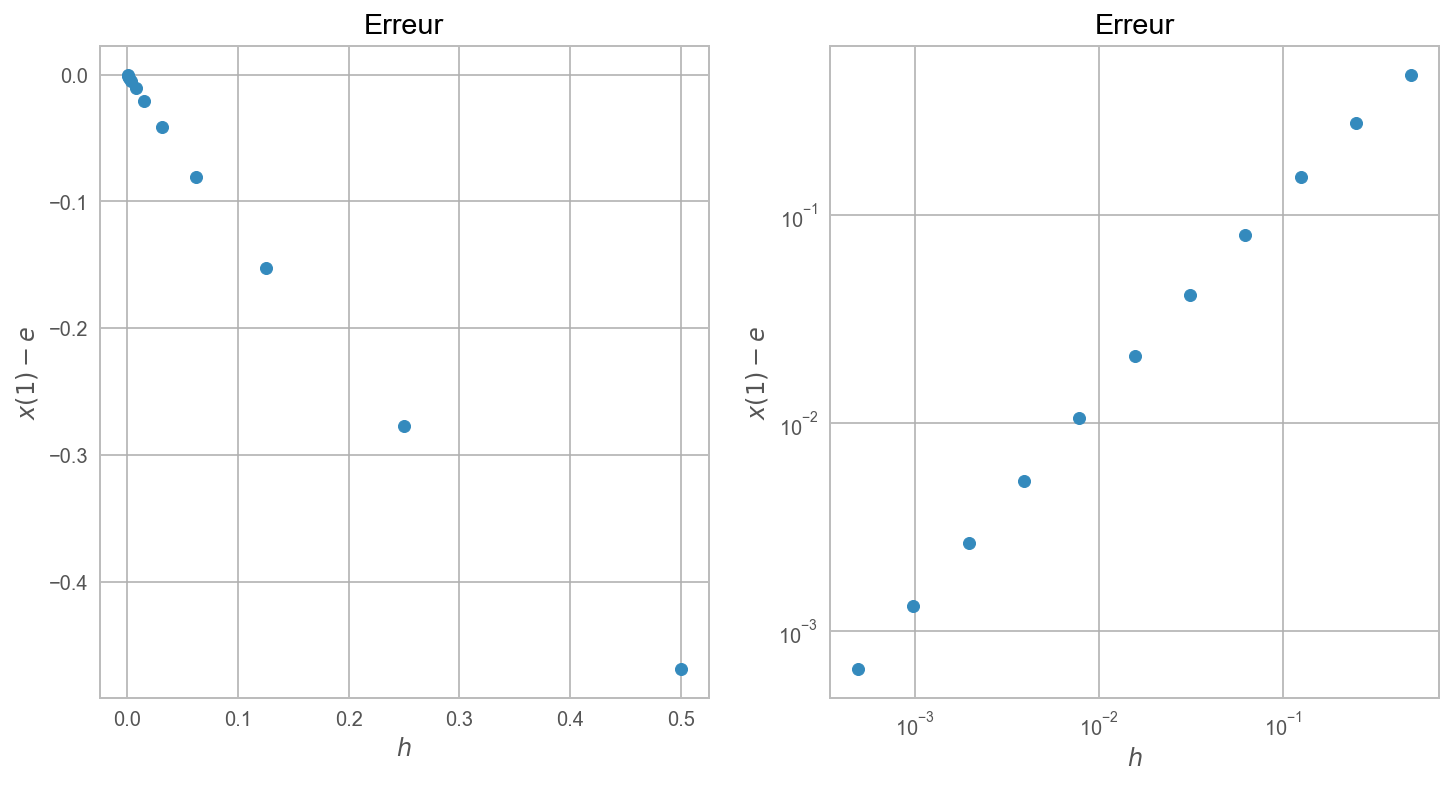

In [6]:
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 2, 1)
ax.scatter(vh, ve - np.exp(1))
ax.set_title("Erreur")
ax.set_xlabel('$h$')
ax.set_ylabel('$x(1)-e$')
axl = fig.add_subplot(1, 2, 2)
axl.set_yscale('log')
axl.set_xscale('log')
axl.scatter(vh, abs(ve - np.exp(1)))
axl.set_title("Erreur")
axl.set_xlabel('$h$')
axl.set_ylabel('$x(1)-e$')

plt.savefig("TP05_edo/exo4.png")

#### Exercice 5

On considère le problème de Cauchy pour $f(t, x) = x + \cos(t)$ et $(t_0, x_0)=(0,-1/2)$.

> * Trouvez explicitement la solution (essayez $x(t)=A cos(t) + B sin(t)$).
> * Construire un script donnant la solution calculée par le schéma d'Euler sur l'intervalle $[0, 10]$ avec un pas $h=10/N$, $N\in\mathbb{N}$.
> * Testez plusieurs valeurs de $N$ et comparez les différentes approximations obtenues avec la solution exacte.

**Correction**

On cherche une solution de la forme $x(t)=A\cos(t)+B\sin(t)$. On a
$x'(t) - x(t) = -(A+B)\sin(t) + (B-A)\cos(t)$. Il faut donc avoir
$B=-A$ et $B-A=1$. La solution est donc
$$ x(t) = \tfrac{1}{2} \bigl( \sin(t) - \cos(t) \bigr).$$
On vérifie alors que l'on a bien $x(0)=-1/2$.

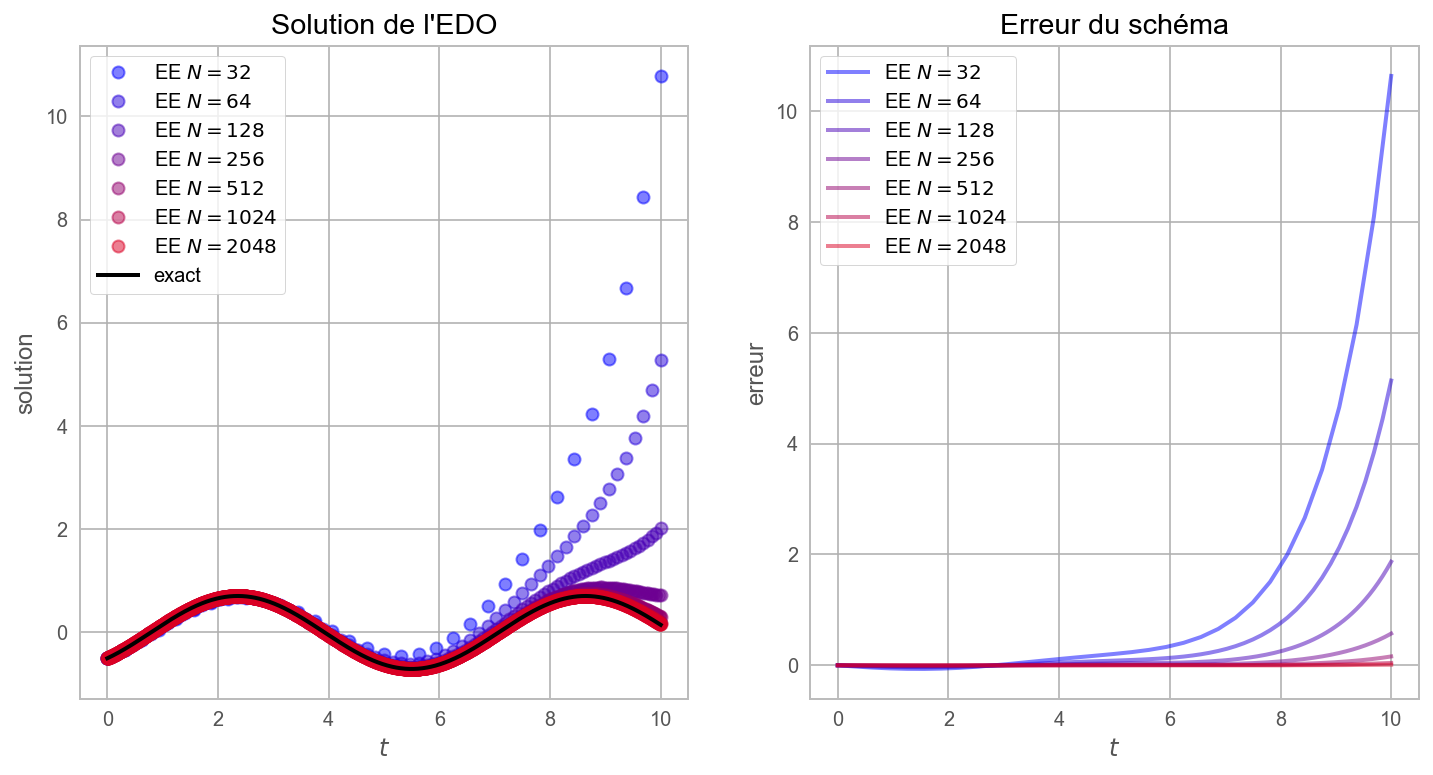

In [8]:
t0, x0 = 0., -.5
T = 10

def sol(t):
    return .5*(np.sin(t) - np.cos(t))

fig = plt.figure(figsize=(12, 6))
axf = fig.add_subplot(1, 2, 1)
axe = fig.add_subplot(1, 2, 2)

liste_N = 2**np.arange(5, 12)
for k, N in enumerate(liste_N):
    c = (k/len(liste_N), 0, 1-k/len(liste_N))
    t, x = sedo.my_euler(t0, x0, T, N, f.my_f)
    axf.plot(
        t, x,
        lw=2, color=c, alpha=.5,
        marker='o', linestyle='None',
        label=f'EE $N={N}$'
    )
    axe.plot(
        t, x - sol(t),
        lw=2, color=c, alpha=.5,
        label=f'EE $N={N}$'
    )

tt = np.linspace(t0, T, 1025)
axf.plot(
    tt, sol(tt),
    color='black', lw=2,
    label='exact'
)
axf.legend()
axf.set_xlabel('$t$')
axf.set_ylabel('solution')
axf.set_title("Solution de l'EDO")
axe.legend()
axe.set_xlabel('$t$')
axe.set_ylabel('erreur')
axe.set_title("Erreur du schéma")

plt.savefig("TP05_edo/exo5.png")